# Two images that look similar to us, different predictions for a model

An experiment using the **provided RTS photo**, with no fabricated scores. Run the cells in order using the project's `uv` environment (`uv sync`, then `uv run jupyter lab`). Saved outputs also allow immediate viewing.

1. Reversible, lossless transformation: exact identity, **100%**.
2. Bounded adversarial perturbation optimized on ResNet-18: visual comparison and model scores.
3. PNG export and verification after reloading; JPEG and a second model to explore limitations.

**What the Grok screenshot means.** The study [Provably Unlearnable Data Examples, NDSS 2025](https://www.ndss-symposium.org/ndss-paper/provably-unlearnable-data-examples/) and its [official code](https://github.com/NeuralSec/certified-data-learnability) address a **training dataset**. Certification through parameter smoothing is defined within a specific $(q,\eta)$ framework. A pair of photos and a similarity score cannot reproduce or validate this certification. We therefore do not present the following experiment as an implementation of PUE.

For the concrete goal of “nearly the same photo, different prediction,” we use adversarial optimization with projected gradients. This follows research on [adversarial examples](https://arxiv.org/abs/1412.6572) and [iterative attacks](https://arxiv.org/abs/1611.01236). There is no guarantee of invisibility to every observer or of an effect on every AI model. A lower score does not imply protection against training.

In [1]:
from pathlib import Path
from io import BytesIO
import hashlib, json, platform
import requests
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image, ImageOps
import torch
import torch.nn.functional as F
import torchvision
from torchvision.models import resnet18, ResNet18_Weights, mobilenet_v3_small, MobileNet_V3_Small_Weights
from torchvision.transforms import functional as TF
from skimage.metrics import structural_similarity, peak_signal_noise_ratio
from IPython.display import display

ROOT = Path.cwd()
if not (ROOT / "pyproject.toml").exists() and (ROOT.parent / "pyproject.toml").exists():
    ROOT = ROOT.parent
DATA, OUT = ROOT / "data", ROOT / "outputs"
DATA.mkdir(exist_ok=True); OUT.mkdir(exist_ok=True)
# Caches stay in the project, including on machines with restricted permissions.
torch.hub.set_dir(str(ROOT / ".cache" / "torch"))
torch.manual_seed(17)
np.random.seed(17)
torch.set_num_threads(min(4, torch.get_num_threads()))
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Python", platform.python_version(), "| torch", torch.__version__, "| torchvision", torchvision.__version__, "|", DEVICE)

/home/charly/.config/matplotlib is not a writable directory


Matplotlib created a temporary cache directory at /tmp/matplotlib-6x4ctth1 because there was an issue with the default path (/home/charly/.config/matplotlib); it is highly recommended to set the MPLCONFIGDIR environment variable to a writable directory, in particular to speed up the import of Matplotlib and to better support multiprocessing.


Python 3.12.14 | torch 2.15.0+cpu | torchvision 0.29.2+cpu | cpu


## 1. Load and display the photo

The downloaded file is preserved intact. To limit CPU computation time, the experiment uses a version with a longest side of 512 pixels, **without cropping**. All subsequent comparisons use this same reference; the initial resizing is not part of the identity transformation.

Source: (1505, 2000) | working reference: (385, 512)
Source SHA-256: ac9af8d30408fd04982a0905d36b0900ecf04c0581a16ac8ba92277f39b6f627


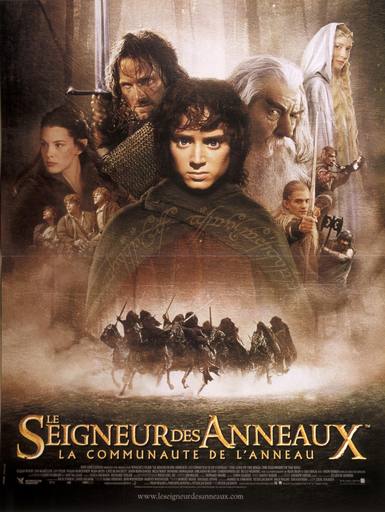

In [2]:
URL = "https://img.rts.ch/articles/2019/image/519ln2-27739145.image?w=0&h=NaN"
source = DATA / "source_rts.image"
if not source.exists():
    response = requests.get(URL, timeout=60)
    response.raise_for_status()
    Image.open(BytesIO(response.content)).verify()
    source.write_bytes(response.content)
photo = ImageOps.exif_transpose(Image.open(source)).convert("RGB")
reference = photo.copy()
reference.thumbnail((512, 512), Image.Resampling.LANCZOS)
a = np.array(reference)
reference.save(OUT / "reference.png")
print("Source:", photo.size, "| working reference:", reference.size)
print("Source SHA-256:", hashlib.sha256(source.read_bytes()).hexdigest())
display(reference)

## 2. Minimal transformation: horizontal mirroring applied twice

This is a reversible pixel transformation with no noise or lossy compression. Equality applies to the decoded RGB pixels, not to the file bytes.

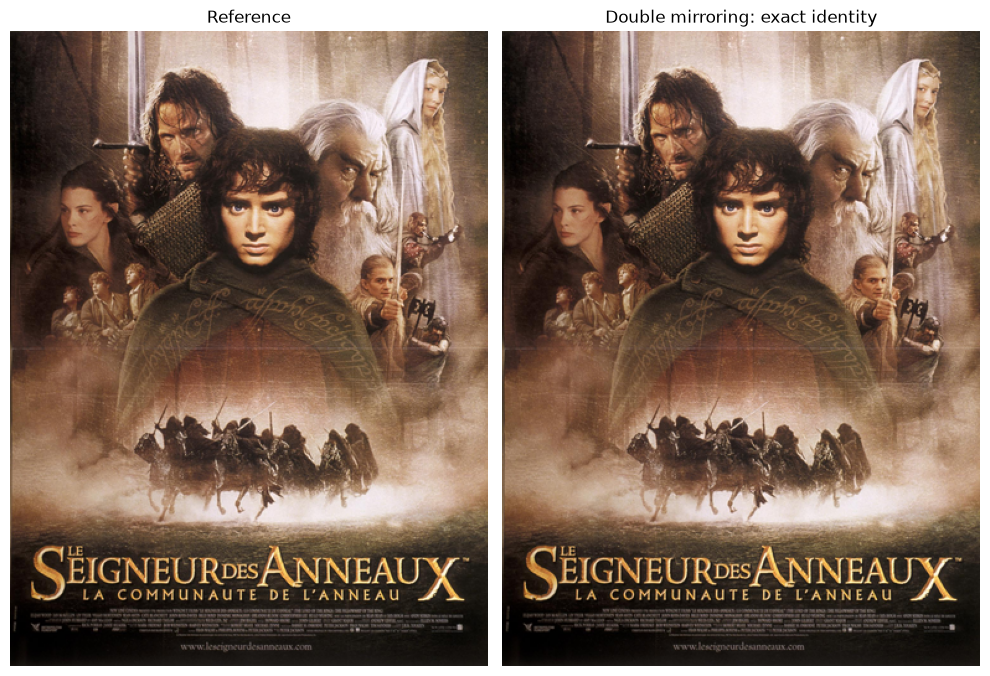

,Identical RGB pixels (%),MAE similarity (%),SSIM × 100,PSNR (dB),Max difference (levels / 255)
Identity control,100.0,100.0,100.0,inf,0.0


In [3]:
identical = ImageOps.mirror(ImageOps.mirror(reference))
b = np.array(identical)

def visual_metrics(x, y):
    d = x.astype(np.float64) - y.astype(np.float64)
    mse = float(np.mean(d ** 2))
    return {
        "Identical RGB pixels (%)": 100 * np.mean(np.all(x == y, axis=-1)),
        "MAE similarity (%)": 100 * (1 - np.mean(np.abs(d)) / 255),
        "SSIM × 100": 100 * structural_similarity(x, y, channel_axis=2, data_range=255),
        "PSNR (dB)": float("inf") if mse == 0 else peak_signal_noise_ratio(x, y, data_range=255),
        "Max difference (levels / 255)": float(np.max(np.abs(d))),
    }

def show_pair(x, y, title):
    fig, ax = plt.subplots(1, 2, figsize=(10, 7))
    for axis, im, label in zip(ax, [x, y], ["Reference", title]):
        axis.imshow(im); axis.set_title(label); axis.axis("off")
    plt.tight_layout(); plt.show()

assert np.array_equal(a, b)
show_pair(a, b, "Double mirroring: exact identity")
display(pd.DataFrame([visual_metrics(a, b)], index=["Identity control"]).round(6))

## 3. Define a comparison from a model's perspective

The model is [ResNet-18 pretrained on ImageNet](https://docs.pytorch.org/vision/stable/models/generated/torchvision.models.resnet18.html). Weights (~45 MB) are downloaded on the first run. We retain its standard preprocessing: shortest side 256, center crop 224, ImageNet normalization. The model therefore only analyzes this crop.

We compare its **prediction distributions** $p$ and $q$ using:

$$S_{AI}(p,q)=100\left(1-\frac12\sum_{k=1}^{1000}|p_k-q_k|\right).$$

This is the overlap between distributions: 100 for identical distributions, close to zero when their probabilities concentrate on different classes. This percentage is **neither a human judgment nor a probability that the photos are identical**. Softmax probabilities are not necessarily calibrated. ImageNet class names are in English.

SSIM × 100 measures structural similarity, not the percentage of observers unable to see the modification.

In [4]:
weights = ResNet18_Weights.DEFAULT
model = resnet18(weights=weights).to(DEVICE).eval()
model.requires_grad_(False)
labels = weights.meta["categories"]
mean = torch.tensor([.485, .456, .406], device=DEVICE)[None, :, None, None]
std = torch.tensor([.229, .224, .225], device=DEVICE)[None, :, None, None]

def tensor(im):
    return TF.to_tensor(im).unsqueeze(0).to(DEVICE)

def preprocess(t):
    t = TF.resize(t, 256, antialias=True)
    t = TF.center_crop(t, [224, 224])
    return (t - mean) / std

def logits(t, net=model):
    return net(preprocess(t))

@torch.no_grad()
def predict(im, net=model):
    return logits(tensor(im), net).softmax(-1)[0].cpu()

def ai_score(p, q):
    return float((1 - .5 * (p - q).abs().sum()).clamp(0, 1) * 100)

def top5(p):
    values, ids = p.topk(5)
    return pd.DataFrame({"Class": [labels[i] for i in ids.tolist()], "Probability (%)": values.numpy() * 100})

p0 = predict(reference)
p_identity = predict(identical)
assert torch.equal(p0, p_identity)
print(f"Control AI similarity: {ai_score(p0, p_identity):.6f} %")
display(top5(p0).round(3))

Control AI similarity: 100.000000 %


,Class,Probability (%)
0,altar,42.090
1,fountain,13.862
2,vault,5.164
3,tray,3.851
4,chain mail,3.836


## 4. Optimize a small perturbation with an explicit budget

We choose a target class different from the initial prediction (the twentieth highest initial class, to reduce overlap without imposing arbitrary content). For each budget $\varepsilon\in\{1,2,4\}/255$, we minimize cross-entropy toward this class using 80 signed gradient steps with projection:

$$x_{t+1}=\mathrm{clip}_{[0,1]\cap[x-\varepsilon,x+\varepsilon]}\left(x_t-\alpha\,\mathrm{sign}(\nabla_{x_t}\mathrm{CE}(f(x_t),c))\right).$$

The noise is computed from the model, not chosen at random. Scores are evaluated **after rounding to 8-bit RGB**: the exported PNG must produce the measured effect. The maximum budget remains 4 levels out of 255 per channel. Visibility depends on the content, screen, and zoom.

The selection criterion is stated in advance: the smallest budget producing AI overlap ≤ 10%, SSIM ≥ 98, and a class change. If no candidate succeeds, we report the failed criterion and retain the candidate with the lowest overlap. No score is forced.

In [5]:
x0 = tensor(reference)
original_class = int(p0.argmax())
target = int(p0.topk(20).indices[-1])
print("Initial class:", labels[original_class], "| target:", labels[target])
STEPS = 80
BUDGETS = [1, 2, 4]

def quantize(t):
    return t.detach().clamp(0, 1).mul(255).round().byte()[0].permute(1, 2, 0).cpu().numpy()

def attack(eps_levels):
    eps = eps_levels / 255
    alpha = .5 / 255
    current = x0.clone()
    best_score, best_image = float("inf"), a.copy()
    history = []
    for step in range(STEPS):
        current = current.detach().requires_grad_(True)
        loss = F.cross_entropy(logits(current), torch.tensor([target], device=DEVICE))
        grad, = torch.autograd.grad(loss, current)
        with torch.no_grad():
            current = current - alpha * grad.sign()
            current = torch.maximum(torch.minimum(current, x0 + eps), x0 - eps).clamp(0, 1)
        if (step + 1) % 10 == 0:
            candidate = quantize(current)
            p = predict(Image.fromarray(candidate))
            score = ai_score(p0, p)
            history.append({"budget": eps_levels, "iteration": step + 1, "AI similarity (%)": score})
            if score < best_score:
                best_score, best_image = score, candidate.copy()
    return best_image, history

candidates, rows, histories = [], [], []
for budget in BUDGETS:
    adv, history = attack(budget)
    p = predict(Image.fromarray(adv))
    row = {"Budget /255": budget, **visual_metrics(a, adv), "AI similarity (%)": ai_score(p0, p),
           "Final class": labels[int(p.argmax())], "Class changed": int(p.argmax()) != original_class}
    assert row["Max difference (levels / 255)"] <= budget
    candidates.append((adv, p)); rows.append(row); histories.extend(history)
    print(f"Budget {budget}/255 : AI similarity {row['AI similarity (%)']:.3f} %, SSIM {row['SSIM × 100']:.3f}")
results = pd.DataFrame(rows)
display(results.round(4))
eligible = results[(results["AI similarity (%)"] <= 10) & (results["SSIM × 100"] >= 98) & results["Class changed"]]
selected = int(eligible.index[0]) if len(eligible) else int(results["AI similarity (%)"].idxmin())
adv, p_adv = candidates[selected]
print("Criterion met:", bool(len(eligible)), "| selected budget:", BUDGETS[selected], "/255")

Initial class: altar | target: church


Budget 1/255 : AI similarity 0.731 %, SSIM 99.821


Budget 2/255 : AI similarity 0.491 %, SSIM 99.420


Budget 4/255 : AI similarity 0.491 %, SSIM 98.715


,Budget /255,Identical RGB pixels (%),MAE similarity (%),SSIM × 100,PSNR (dB),Max difference (levels / 255),AI similarity (%),Final class,Class changed
0,1,42.6243,99.8139,99.8211,51.3681,1.0,0.7311,church,True
1,2,41.9506,99.6529,99.4205,46.1120,2.0,0.4908,church,True
2,4,42.0196,99.5086,98.7150,42.4711,4.0,0.4908,church,True


Criterion met: True | selected budget: 1 /255


## 5. View both images and understand the scores

Images are displayed at the same size and scale. The difference map is amplified to make the noise visible; it is not the protected image. Zooming may reveal differences hidden at normal display size.

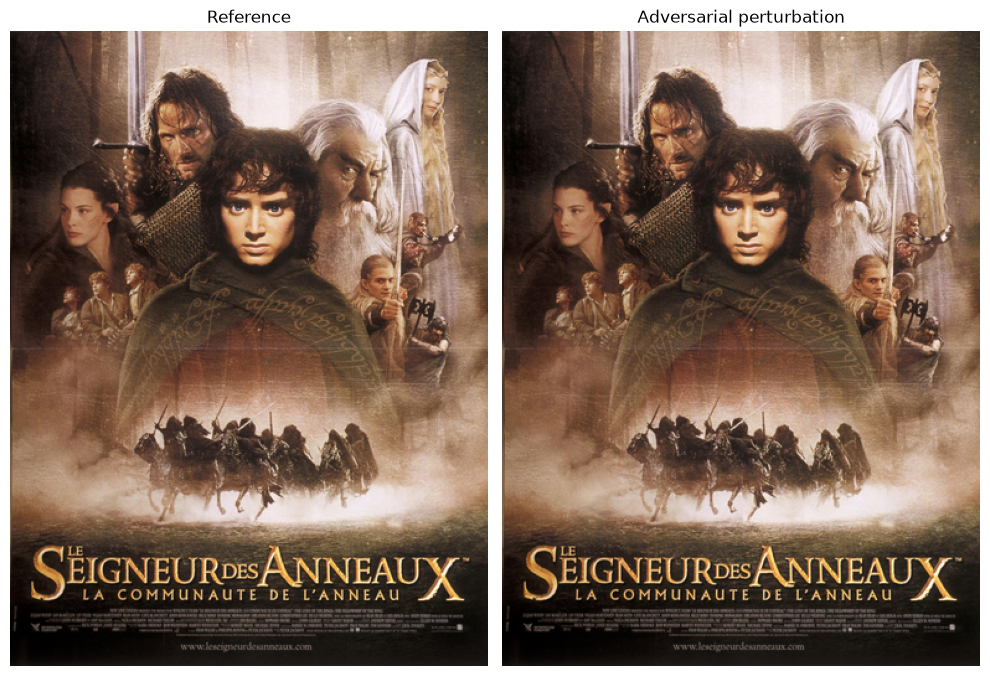

,Identical RGB pixels (%),MAE similarity (%),SSIM × 100,PSNR (dB),Max difference (levels / 255),AI similarity (%)
Comparison,,,,,,
Identity,100.0000,100.0000,100.0000,inf,0.0,100.0000
Adversarial,42.6243,99.8139,99.8211,51.3681,1.0,0.7311


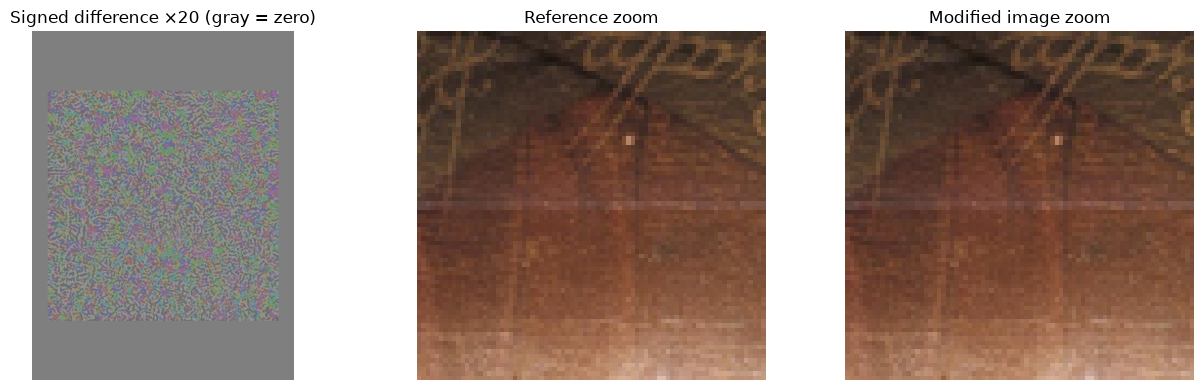

Predictions before


,Class,Probability (%)
0,altar,42.090
1,fountain,13.862
2,vault,5.164
3,tray,3.851
4,chain mail,3.836


Predictions after


,Class,Probability (%)
0,church,99.703003
1,vault,0.057000
2,altar,0.040000
3,Eskimo dog,0.025000
4,monastery,0.022000


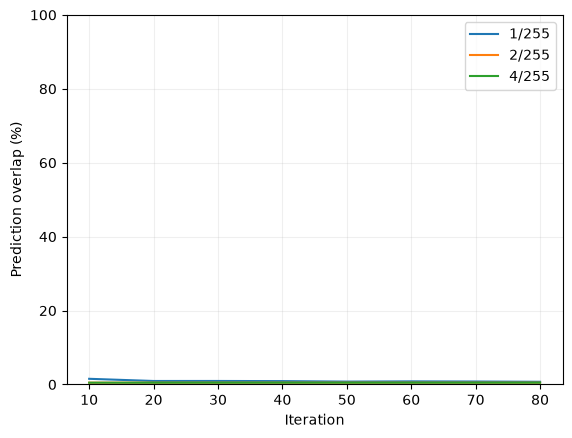

In [6]:
show_pair(a, adv, "Adversarial perturbation")
display(pd.DataFrame([
    {"Comparison": "Identity", **visual_metrics(a, b), "AI similarity (%)": ai_score(p0, p_identity)},
    {"Comparison": "Adversarial", **visual_metrics(a, adv), "AI similarity (%)": ai_score(p0, p_adv)},
]).set_index("Comparison").round(4))
fig, axes = plt.subplots(1, 3, figsize=(13, 4))
diff = adv.astype(float) - a.astype(float)
axes[0].imshow(np.clip(.5 + diff * 20 / 255, 0, 1)); axes[0].set_title("Signed difference ×20 (gray = zero)")
h, w = a.shape[:2]; ys, xs = slice(h//2-40, h//2+40), slice(w//2-40, w//2+40)
axes[1].imshow(a[ys, xs], interpolation="nearest"); axes[1].set_title("Reference zoom")
axes[2].imshow(adv[ys, xs], interpolation="nearest"); axes[2].set_title("Modified image zoom")
for ax in axes: ax.axis("off")
plt.tight_layout(); plt.show()
print("Predictions before")
display(top5(p0).round(3))
print("Predictions after")
display(top5(p_adv).round(3))
history = pd.DataFrame(histories)
for budget, frame in history.groupby("budget"):
    plt.plot(frame["iteration"], frame["AI similarity (%)"], label=f"{budget}/255")
plt.xlabel("Iteration"); plt.ylabel("Prediction overlap (%)")
plt.ylim(0, 100); plt.legend(); plt.grid(alpha=.2); plt.show()

## 6. Export, reload, and test fragility

PNG preserves the pixels. JPEG may destroy the perturbation. We also compare a MobileNet model never used during optimization: this tests limited transfer without representing every AI model. Both models use the same standard preprocessing here (256, then 224).

In [7]:
path = OUT / "adversarial.png"
Image.fromarray(adv).save(path)
reloaded = Image.open(path).convert("RGB")
assert np.array_equal(np.array(reloaded), adv)
p_reload = predict(reloaded)
assert torch.allclose(p_reload, p_adv, atol=1e-6)
Image.fromarray(adv).save(OUT / "adversarial_q90.jpg", quality=90)
jpeg = Image.open(OUT / "adversarial_q90.jpg").convert("RGB")
other_weights = MobileNet_V3_Small_Weights.DEFAULT
other = mobilenet_v3_small(weights=other_weights).to(DEVICE).eval().requires_grad_(False)
p_other_clean, p_other_adv = predict(reference, other), predict(reloaded, other)
robustness = pd.DataFrame([
    {"Test": "ResNet-18 / PNG", "AI similarity (%)": ai_score(p0, p_reload)},
    {"Test": "ResNet-18 / JPEG quality 90", "AI similarity (%)": ai_score(p0, predict(jpeg))},
    {"Test": "MobileNet / PNG (transfer)", "AI similarity (%)": ai_score(p_other_clean, p_other_adv)},
])
display(robustness.round(3))
results.to_csv(OUT / "measurements.csv", index=False)
robustness.to_csv(OUT / "robustness.csv", index=False)
metadata = {"source": URL, "source_sha256": hashlib.sha256(source.read_bytes()).hexdigest(),
            "dimensions": reference.size, "seed": 17, "steps": STEPS, "budgets": BUDGETS,
            "selected_budget": BUDGETS[selected], "criterion_met": bool(len(eligible)),
            "torch": torch.__version__, "torchvision": torchvision.__version__, "device": str(DEVICE)}
(OUT / "experiment.json").write_text(json.dumps(metadata, ensure_ascii=False, indent=2))
print("Files available in", OUT)

,Test,AI similarity (%)
0,ResNet-18 / PNG,0.731
1,ResNet-18 / JPEG quality 90,4.733
2,MobileNet / PNG (transfer),92.866


Files available in /home/charly/Documents/Projets/adversarial-visual-content/outputs


## Interpreting the result

The control verifies exact identity and an AI score of 100%. The perturbation actually changes pixels, even if the images may appear identical at normal size. High SSIM may coexist with strongly divergent predictions from the attacked model; these two measurements answer different questions.

The class change and distribution overlap demonstrate classifier sensitivity. They do not prove that the model no longer recognizes any content in the photo or that its internal representation is entirely different. Cropping, compression, another model, or another task may change the conclusions.

Reproducing **PUE** would require a separate experiment with a labeled training set, a clean test set, model training, and certification under the paper's assumptions. This notebook provides no such certification and demonstrates no protection against scraping, deepfakes, or training.